# Data Visualization

This notebook visualizes the main patterns in renewable electricity production in Italy from 2000 to 2024.

The visual analysis focuses on:
- the evolution of total renewable electricity production over time;
- changes in the contribution of different renewable energy sources;
- differences in renewable electricity production across Italian regions.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load the cleaned gross renewable electricity production dataset.
df = pd.read_csv("../data/processed/terna_renewable_production_2000_2024.csv")

In [3]:
# Aggregate gross renewable electricity production by year.
annual_production = (
    df.groupby("year")["production_GWh"]
    .sum()
)

annual_production.head()

year
2000    50978.473439
2001    54458.374458
2002    48298.552613
2003    47060.825353
2004    54124.627682
Name: production_GWh, dtype: float64

## 1. Evolution of Renewable Electricity Production

The following chart shows the evolution of total gross renewable electricity production in Italy between 2000 and 2024.

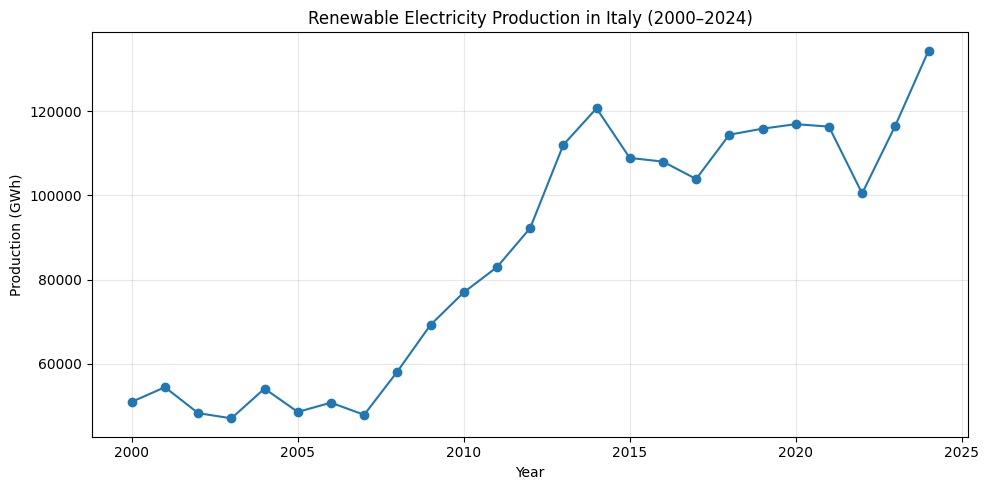

In [4]:
# Plot the evolution of total renewable electricity production over time.
plt.figure(figsize=(10, 5))

plt.plot(
    annual_production.index,
    annual_production.values,
    marker="o"
)

plt.title("Renewable Electricity Production in Italy (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Production (GWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key finding
Gross renewable electricity production shows a clear long-term upward trend, increasing from approximately 51,000 GWh in 2000 to more than 134,000 GWh in 2024.

The growth was not uniform: the series shows substantial year-to-year fluctuations, particularly in the later part of the period.

## 2. Renewable Energy Sources Over Time

The following analysis visualizes how electricity production from different renewable energy sources evolved between 2000 and 2024.

In [5]:
# Aggregate annual production by source and reshape the data for visualization.
annual_by_source = (
    df.groupby(["year", "renewable_source"])["production_GWh"]
    .sum()
    .unstack()
)

annual_by_source.head()

renewable_source,Bioenergie,Eolico,Fotovoltaico,Geotermoelettrico,Idrico
year,,,,,
2000,1504.469312,563.072870,6.293099,4705.1916,44199.446558
2001,1958.092169,1178.591264,4.847992,4506.5693,46810.273733
2002,2708.607207,1404.233409,4.079782,4662.2728,39519.359415
2003,3587.101982,1458.447683,5.011693,5340.4626,36669.801395
2004,4498.899074,1846.544155,4.041728,5437.2663,42337.876426


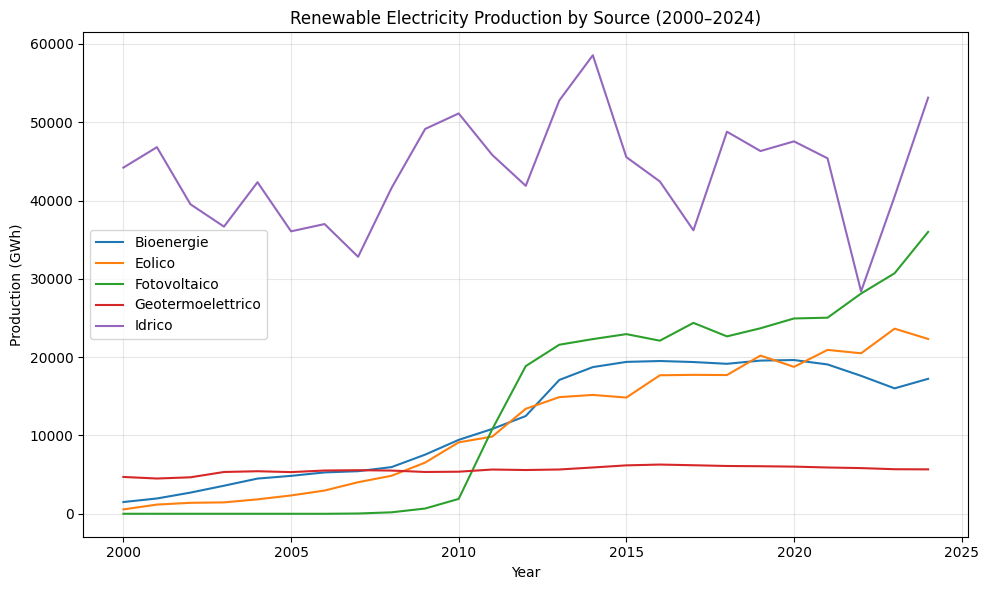

In [6]:
# Plot the evolution of electricity production for each renewable energy source.
plt.figure(figsize=(10, 6))

for source in annual_by_source.columns:
    plt.plot(
        annual_by_source.index,
        annual_by_source[source],
        label=source
    )

plt.title("Renewable Electricity Production by Source (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Production (GWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key finding

The composition of renewable electricity production changed substantially between 2000 and 2024.

Hydropower remained an important source throughout the period, but its dominance decreased as other renewable technologies expanded. Solar production increased sharply, especially after 2010, while wind and bioenergy also increased substantially. Geothermal production remained comparatively stable.

In [7]:
# Calculate each source's percentage share of total renewable production by year.
source_share = (
    annual_by_source
    .div(annual_by_source.sum(axis=1), axis=0)
    * 100
)

source_share.loc[[2000, 2024]]

renewable_source,Bioenergie,Eolico,Fotovoltaico,Geotermoelettrico,Idrico
year,,,,,
2000,2.951185,1.104531,0.012345,9.229762,86.702178
2024,12.829012,16.613806,26.789053,4.223781,39.544349


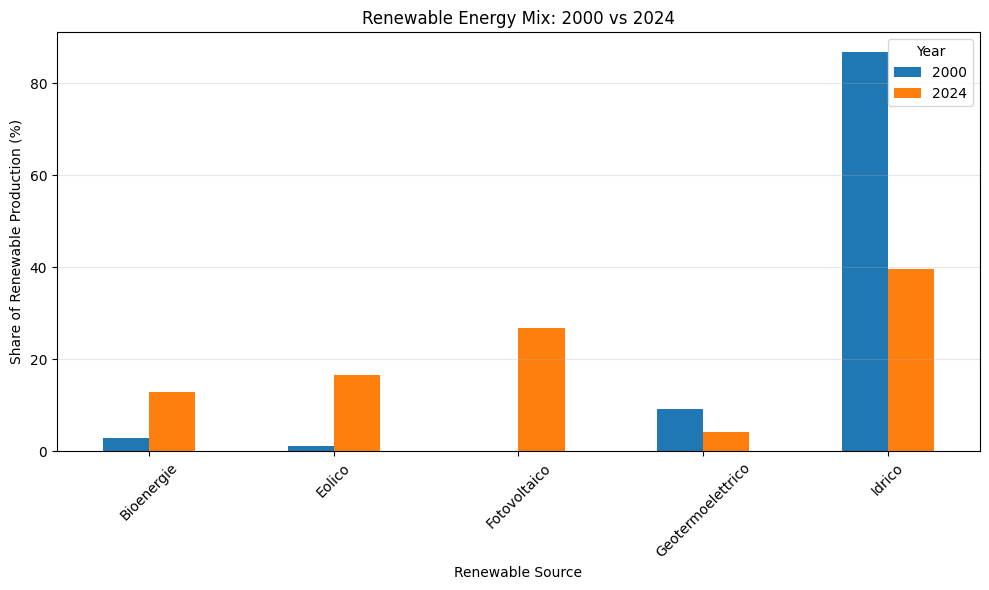

In [8]:
# Compare the renewable energy mix in 2000 and 2024.
source_share.loc[[2000, 2024]].T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Renewable Energy Mix: 2000 vs 2024")
plt.xlabel("Renewable Source")
plt.ylabel("Share of Renewable Production (%)")
plt.xticks(rotation=45)
plt.legend(title="Year")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Key finding

The renewable electricity mix changed profoundly between 2000 and 2024.

In 2000, hydropower accounted for approximately **86.7%** of renewable electricity production. By 2024, its share had fallen to approximately **39.5%**, while solar reached **26.8%**, wind **16.6%**, and bioenergy **12.8%**.

This comparison highlights the substantial diversification of Italy's renewable electricity mix over the period analyzed.

## 3. Regional Differences

The following visualization compares gross renewable electricity production across Italian regions in 2024.

In [9]:
# Aggregate 2024 gross renewable electricity production by region and sort for visualization.
regional_production_2024 = (
    df[df["year"] == 2024]
    .groupby("region")["production_GWh"]
    .sum()
    .sort_values()
)

regional_production_2024

region
Liguria                    798.471109
Molise                    1189.105748
Marche                    2023.027029
Umbria                    2168.309014
Abruzzo                   2809.413912
Friuli-Venezia Giulia     3806.539214
Basilicata                3935.583651
Valle d'Aosta             3947.725697
Sardegna                  4324.700666
Lazio                     4727.916061
Calabria                  5114.440699
Campania                  6298.016764
Emilia-Romagna            6761.829951
Sicilia                   7134.335963
Toscana                   8519.475942
Veneto                    9926.743558
Puglia                   12617.291966
Piemonte                 12976.197948
Trentino-Alto Adige      14144.146962
Lombardia                21134.233105
Name: production_GWh, dtype: float64

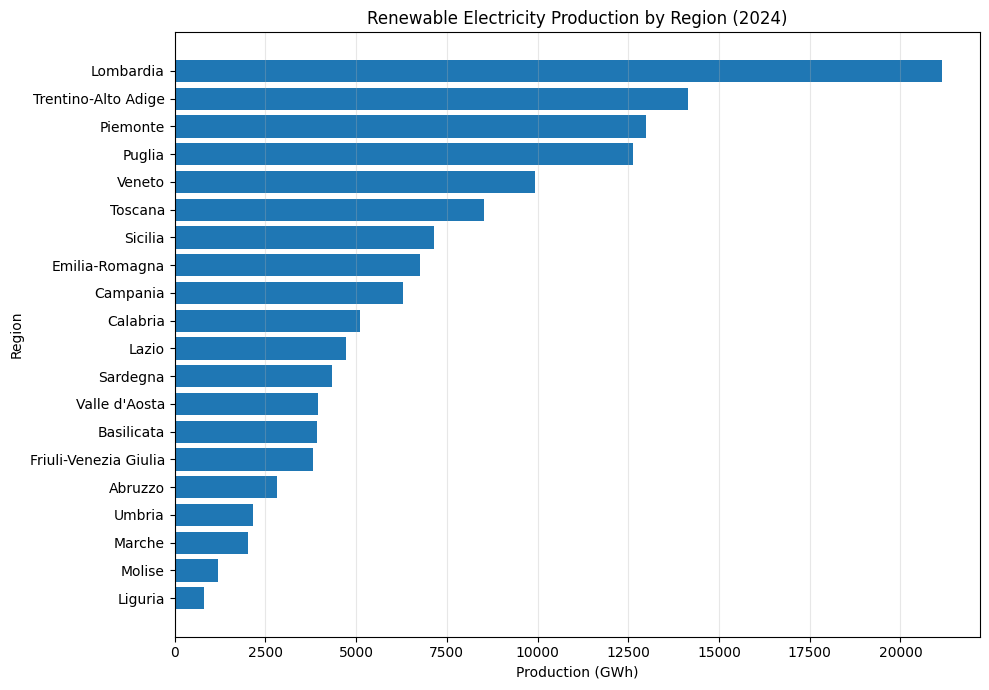

In [10]:
# Plot 2024 gross renewable electricity production by region.
plt.figure(figsize=(10, 7))

plt.barh(
    regional_production_2024.index,
    regional_production_2024.values
)

plt.title("Renewable Electricity Production by Region (2024)")
plt.xlabel("Production (GWh)")
plt.ylabel("Region")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Key finding

Renewable electricity production varies substantially across Italian regions.

In 2024, **Lombardy** recorded the highest absolute production, with approximately **21,134 GWh**, followed by **Trentino-Alto Adige**, **Piedmont**, and **Puglia**.

These values represent absolute electricity production and do not account for differences in population, electricity consumption, or regional size.

In [11]:
# Calculate the absolute change in regional production between 2000 and 2024.
regional_production_2000 = (
    df[df["year"] == 2000]
    .groupby("region")["production_GWh"]
    .sum()
)

regional_change = (
    regional_production_2024
    - regional_production_2000
).sort_values()

regional_change

region
Liguria                    544.385734
Umbria                     560.310180
Molise                    1041.685986
Valle d'Aosta             1106.981097
Abruzzo                   1232.357131
Marche                    1519.361474
Friuli-Venezia Giulia     2257.176039
Toscana                   2985.621587
Lazio                     3545.798853
Basilicata                3739.470481
Trentino-Alto Adige       3798.735662
Sardegna                  4178.620687
Calabria                  4400.874641
Campania                  5471.547599
Emilia-Romagna            5587.398113
Veneto                    5760.711560
Piemonte                  6545.761595
Sicilia                   7034.985483
Lombardia                 9777.380041
Puglia                   12289.867576
Name: production_GWh, dtype: float64

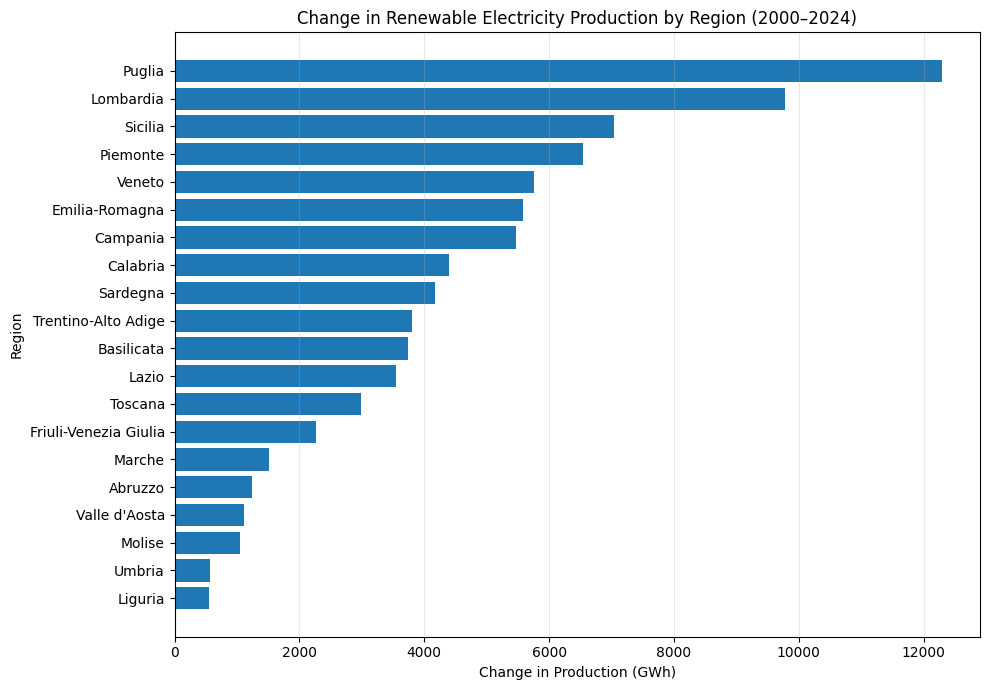

In [12]:
# Plot the absolute change in renewable electricity production by region.
plt.figure(figsize=(10, 7))

plt.barh(
    regional_change.index,
    regional_change.values
)

plt.title("Change in Renewable Electricity Production by Region (2000–2024)")
plt.xlabel("Change in Production (GWh)")
plt.ylabel("Region")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Key finding

All Italian regions recorded an increase in gross renewable electricity production between 2000 and 2024.

**Puglia** experienced the largest absolute increase, with approximately **12,290 additional GWh**, followed by **Lombardy** with approximately **9,777 GWh** and **Sicily** with approximately **7,035 GWh**.

The magnitude of the increase varied considerably across regions, highlighting substantial geographical differences in the expansion of renewable electricity production.